## Backend

Backendiä kokeillessa tensorflow tuotti heikompaa dataa kuin pytorch (parhaimmillaan pääsin 93,33% ja validation loss jäi suuremmaksi).

In [1]:
import os

os.environ["KERAS_BACKEND"] = "torch"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras.layers import Input, Dense, Flatten
from keras.utils import to_categorical
from keras.models import Sequential
from sklearn.preprocessing import LabelEncoder

## Ladataan data

Ladataan data ja muokataan se dataframeksi, että on helpompi tulkita käsiteltävät piirteet ja kohdearvo.

In [3]:
# Datasetin lataus
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species"
]

df = pd.read_csv(url, header=None, names=columns)

In [4]:
# tarkistetaan että datasetti latautui oikein
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


## Varmistutaan ettei ole tyhjiä arvoja datassa

In [5]:
# Tarkistetaan tyhjät arvot sarakkeittain
df.isna().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

## Jaetaan data piirteisiin ja kohteeseen

Datassa on 4 piirrettä ja 1 kohde. Kohde on nimellä "species". Jaetaan kohteet ja piirteet omiin dataframeihin.

In [6]:
# Jaetaan kohde y:ksi ja piirteet x:ksi
x = df.drop(columns=["species"])
y = df["species"]

## Tarkastellaan kohdeluokkia

In [7]:
print(df["species"].unique())

<StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str


## Johtopäätökset

Ei tyhjiä, ei tarvitse niitä korjata datasta. Datassa on 4 piirrettä ja 3 eri kohdeluokkaa. Kohdeluokat ovat merkkijonoja -> ne pitää muokata eka numeerisiksi, että voi one-hot enkoodata.

## Tutkitaan maksimi- ja minimiarvoja piirteittäin

Katsotaan jokaisen piirteen minimit ja maksimit, jotta nähdään niiden vaihteluvälit.

In [8]:
sepal_length_max = x["sepal_length"].max()
sepal_length_min = x["sepal_length"].min()

sepal_width_max = x["sepal_width"].max()
sepal_width_min = x["sepal_width"].min()

petal_length_max = x["petal_length"].max()
petal_length_min = x["petal_length"].min()

petal_width_max = x["petal_width"].max()
petal_width_min = x["petal_width"].min()

print(f"Verholehden pituus: min {sepal_length_min} cm, max {sepal_length_max} cm")
print(f"Verholehden leveys: min {sepal_width_min} cm, max {sepal_width_max} cm")
print(f"Terälehden pituus: min {petal_length_min} cm, max {petal_length_max} cm")
print(f"Terälehden leveys: min {petal_width_min} cm, max {petal_width_max} cm")

Verholehden pituus: min 4.3 cm, max 7.9 cm
Verholehden leveys: min 2.0 cm, max 4.4 cm
Terälehden pituus: min 1.0 cm, max 6.9 cm
Terälehden leveys: min 0.1 cm, max 2.5 cm


## Johtopäätökset

Datan piirteiden arvot vaihtelevat eri suuruusluokissa, mutta erot ei ole niin suuria, että skaalaus on tarpeen. Lisäksi skaalattu data suoriutui heikommin kun ei skaalattu. Ei tässä notebookissa kun korjasin sen ottamalla pois jolloin validation loss käyrän heittely väheni ja tarkkuus parani. Lisäksi nopeammin oppi piirteet eli skaalaus heikensi datan oppimista tässä tilanteessa.

## Kohdearvojen käsittely

Ensin LabelEncoderilla numeroidaan kohdearvot numeerisiksi ja sitten one-hot enkoodataan to_categorical funktiolla.

In [9]:
# Muutetaan kohdearvot numeerisiksi
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# One-hot enkoodataan kohdearvot
y_onehot = to_categorical(y_encoded, 3)

## Datan sekoitus

Aluksi sekoitetaan piirteet ja kohteet pitäen ne samoissa kohdissa. Datassa nähtiin, että kohdeluokat oli järjestyksessä. Sekoituksella varmistetaan, että koulutus- ja validointidata sisältävät eri kohdeluokkia. Ennen sekoitusta huomasin heittelyä loss-käyrässä, ja sekoituksen jälkeen oppiminen stabiloitui. Se johtui järjestyneestä datasta jolloin mallit sai liikaa samaa luokkaa koulutuksiin.

In [10]:
# Sekoitetaan havainnot samalla indeksijärjestyksellä
indices = np.arange(len(x))
np.random.seed(0)
np.random.shuffle(indices)

x_random = x.to_numpy()[indices]
y_shuffled = y_onehot[indices]

# Määritellään koulutusosuuden koko
train_size = int(len(x_random) * 0.8)

# Piirteet pidetään alkuperäisinä
x_shuffled = x_random

print("Koulutusluokat:", y_shuffled[:train_size].sum(axis=0))
print("Validointiluokat:", y_shuffled[train_size:].sum(axis=0))
print("Piirteiden shape:", x_shuffled.shape)

Koulutusluokat: [40. 39. 41.]
Validointiluokat: [10. 11.  9.]
Piirteiden shape: (150, 4)


## Tarkistetaan onnistuiko muutokset

In [11]:
# Tarkistetaan piirteet ja onehot muokkaus lukemalla ekat 5
print("Onehot ekat 5:\n")
print(y_shuffled[:5])

Onehot ekat 5:

[[0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [1. 0. 0.]]


## Päätetään mallin input arvo

Vaikka tiedetään että on 4 eri piirrettä, varmistetaan se käsittelyn jälkeen vielä shape-metodilla.

In [12]:
# Tarkistetaan shape oikean inputin määrittämiseksi
x_shuffled.shape

(150, 4)

## Johtopäätökset

Enkoodaus onnistui ja datassa on 3 eri kohdeluokkaa sekä 4 piirrettä. Shufflauksella saadaan varmistettua koulutusta varten monipuolista dataa pienestä datasetistä. 

# Mallinnus

Ennen jokaista mallia resetoidaan kerasin seedi aina samaan eli 0, että tulokset ovat toistettavia ja vertailukelpoisia.

## Neuronien määrien kokeilu

Input pysyy kaikissa malleissa samana ja viimeisessä Dense kerroksessa on 3 neuronia kolmea kohdeluokkaa varten. Kokeillaan ensin miten malli toimii neuroneilla 8, 16, 32, 64.

## Alustetaan mallit

Alustetaan kaikki mallit omilla neuronimäärillä ja samalla optimoijalla. Määritetään stopperi, joka pysäyttää koulutuksen ylioppimisen havaitessaan 5 patiencellä. Lisäksi määritetään absurdin suuri epochien määrä jolloin hitaimmin oppimat mallit pääsevät maaliin ennen pysäytystä.

In [13]:
# Stopperi huomaa kun malli alkaa ylioppia, eli validation loss lähtee nousemaan.
stopper = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [14]:
# Suuri lukema takamaan, että malli ei ali opi.
max_epochs = 1500

In [15]:
# 8 neuronin malli
keras.utils.set_random_seed(0)
model8 = Sequential([
    Input(shape=(4,)), # 4 shapea -> 4 eri piirrettä -> input on oltava 4
    Flatten(), # tehdään yksiulotteiseksi arvot
    Dense(8, activation='relu'),
    Dense(3, activation='softmax') # 3 neuronia 3 luokkaa varten
    ])

# 16 neuronin malli
keras.utils.set_random_seed(0)
model16 = Sequential([
    Input(shape=(4,)), # 4 shapea -> 4 eri piirrettä -> input on oltava 4
    Flatten(), # tehdään yksiulotteiseksi arvot
    Dense(16, activation='relu'),
    Dense(3, activation='softmax') # 3 neuronia 3 luokkaa varten
    ])

# 32 neuronin malli
keras.utils.set_random_seed(0)
model32 = Sequential([
    Input(shape=(4,)), # 4 shapea -> 4 eri piirrettä -> input on oltava 4
    Flatten(), # tehdään yksiulotteiseksi arvot
    Dense(32, activation='relu'),
    Dense(3, activation='softmax') # 3 neuronia 3 luokkaa varten
    ])

# 64 neuronin malli
keras.utils.set_random_seed(0)
model64 = Sequential([
    Input(shape=(4,)), # 4 shapea -> 4 eri piirrettä -> input on oltava 4
    Flatten(), # tehdään yksiulotteiseksi arvot
    Dense(64, activation='relu'),
    Dense(3, activation='softmax') # 3 neuronia 3 luokkaa varten
    ])

model_list = [model8, model16, model32, model64]

### Optimointi ja koulutus

Pidetään batch_size oletuksena (32) ja määritetään se eksplisiittisesti selkeyden vuoksi. Määritetään learning rate 0.001 eli oletusarvoon myös explisiittisesti. Sitten koulutetaan mallit ja annetaan validointiin 20% (30 riviä). Optimoijaksi halusin testata RMSpropia, vaikka adamilla olisi voitu saada nopeemmin koulutettu luokka.

In [16]:
# Alustetaan mallit samalla optimoijalla.

for model in model_list:
    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=0.001),   ## Määritetään eksplisiittisesti learningrate selkeyden vuoksi
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

In [17]:
import time

# Sovitetaan mallit ja luodaan jokaiselle oma historia.

histories = []
training_times = []

## Verbose=0 piilottaa epochit, jotta ei täytä notebookkia
for model in model_list:
    keras.utils.set_random_seed(0)
    start = time.perf_counter()
    history = model.fit(x_shuffled, y_shuffled, epochs=max_epochs, batch_size=32, validation_split=0.2, callbacks=[stopper], verbose=0)
    histories.append(history)

    elapsed = time.perf_counter() - start
    training_times.append(elapsed)

In [18]:
results = []

## HUOM AI:lta pyydetty koodinpätkä, että saadaan data järkevästi vertailtavaan muotoon.
## Epäonnistuin ite täs liian monta kertaa, joten pyysin korjaamaan.
for neurons, history, elapsed in zip(
    [8, 16, 32, 64], histories, training_times
):
    # Etsitään pienimmän validation lossin epoch (jätin tän kun ite en tiennyt mitä tässä tarkalleen tapahtuu)
    best_idx = np.argmin(history.history["val_loss"])

    results.append({
        "Neuronit": neurons,
        "Paras epoch": best_idx + 1,
        "Training loss": history.history["loss"][best_idx],
        "Validation loss": history.history["val_loss"][best_idx],
        "Training accuracy": history.history["accuracy"][best_idx],
        "Validation accuracy": history.history["val_accuracy"][best_idx],
        "Koulutusaika (s)": elapsed
    })

results_df = pd.DataFrame(results)

display(results_df)

,Neuronit,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,8,335,0.217197,0.204643,0.983333,0.966667,5.885220
1,16,226,0.170144,0.154124,0.983333,0.933333,4.083365
2,32,166,0.180704,0.160163,0.983333,0.966667,2.928336
3,64,128,0.166070,0.151355,0.983333,0.966667,2.100844


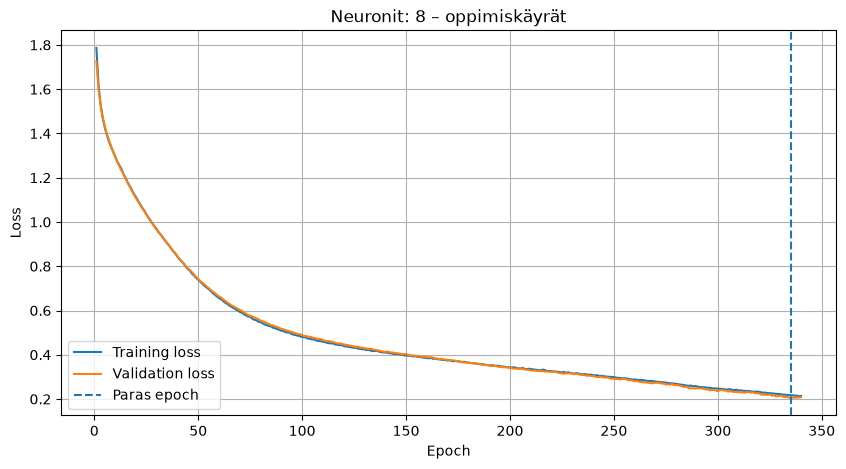

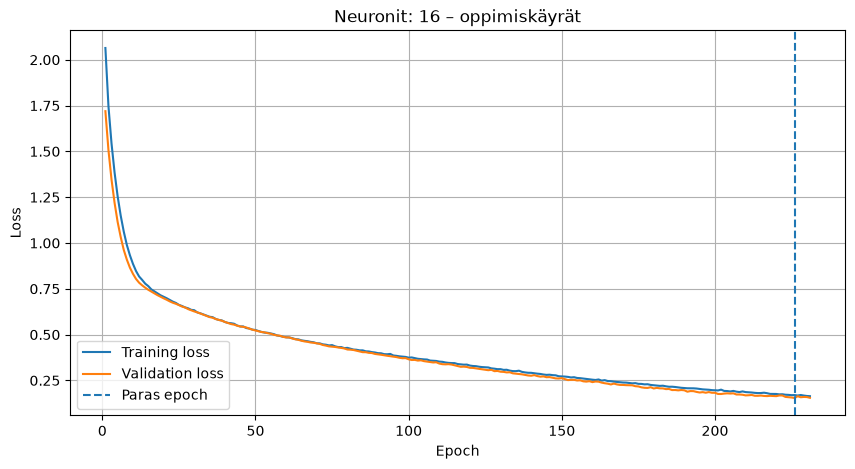

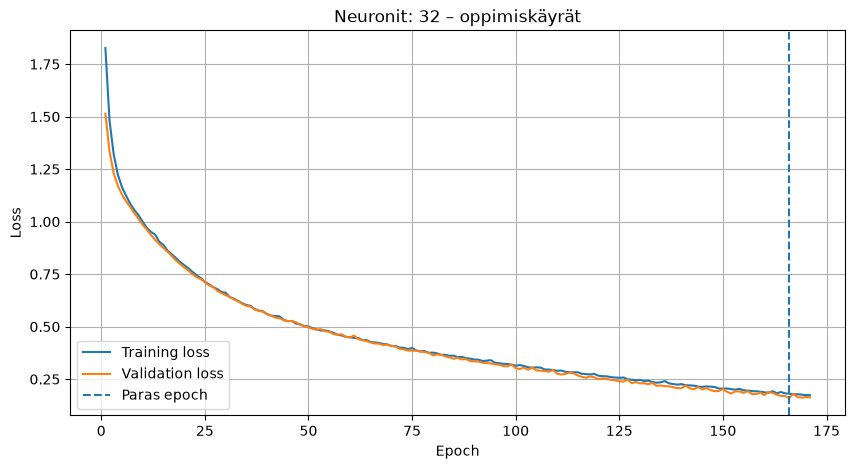

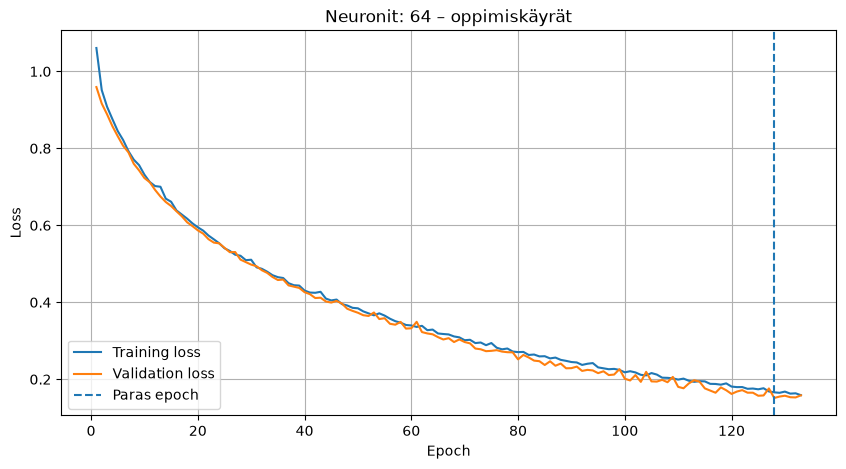

In [19]:
# Piirretään jokaisen neuronimäärän training loss ja validation loss
for neurons, history in zip([8, 16, 32, 64], histories):
    best_epoch = np.argmin(history.history["val_loss"]) + 1
    epochs = range(1, len(history.history["loss"]) + 1)

    plt.figure(figsize=(10, 5))
    plt.plot(epochs, history.history["loss"], label="Training loss")
    plt.plot(epochs, history.history["val_loss"], label="Validation loss")
    plt.axvline(best_epoch, linestyle="--", label="Paras epoch")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Neuronit: {neurons} – oppimiskäyrät")
    plt.legend()
    plt.grid(True)
    plt.show()


## Suoritusajat

In [20]:
for neurons, training_time in zip([8, 16, 32, 64], training_times):
    print(f"\nKoulutusaika neuroneilla {neurons}: {training_time:.2f} s\n")


Koulutusaika neuroneilla 8: 5.89 s


Koulutusaika neuroneilla 16: 4.08 s


Koulutusaika neuroneilla 32: 2.93 s


Koulutusaika neuroneilla 64: 2.10 s



## Johtopäätökset

Neuronimäärillä 8, 16, 32 ja 64 huomataan, että neuronien määrä nostaa tarkkuutta. Lisäksi neuronien määrn kasvattaminen lisäsi validation loss käyrän kohinaa. Visuaalista eroa ei ole 8 ja 16 välillä, kun 32 ja 64 pääsi jo 96,67% validoinnin tarkkuudessa. Kohina oli sen verran suurta 16 hypätessä 32. 8 oppi huomattavasti hitaammin datan vaikka pääsi tavoite tarkkuuteen, joten valitaan 16 ja koitetaan muilla hyperparametreillä optimoida mallia.

## Learning raten määritys

Kokeillaan erikseen 16 neuronin mallia learning rate -arvoilla 0.00001, 0.0003, 0.001 ja 0.003. Pidetään batch size samana eli 32, jotta oppimisnopeuksia voidaan vertailla.

## Mallien luonti

In [21]:
# LR 0.00001
keras.utils.set_random_seed(0)
model16_00001 = Sequential([
    Input(shape=(4,)),
    Flatten(),
    Dense(16, activation='relu'),
    Dense(3, activation='softmax')
])

model16_00001.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# LR 0.00003
keras.utils.set_random_seed(0)
model16_00003 = Sequential([
    Input(shape=(4,)),
    Flatten(),
    Dense(16, activation='relu'),
    Dense(3, activation='softmax')
])

model16_00003.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.00003),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# LR 0.0001
keras.utils.set_random_seed(0)
model16_0001 = Sequential([
    Input(shape=(4,)),
    Flatten(),
    Dense(16, activation='relu'),
    Dense(3, activation='softmax')
])

model16_0001.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

#LR 0.0003
keras.utils.set_random_seed(0)
model16_0003 = Sequential([
    Input(shape=(4,)),
    Flatten(),
    Dense(16, activation='relu'),
    Dense(3, activation='softmax')
    ])

model16_0003.compile(optimizer=keras.optimizers.RMSprop(learning_rate=0.0003),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# LR 0.001
keras.utils.set_random_seed(0)
model16_001 = Sequential([
    Input(shape=(4,)),
    Flatten(),
    Dense(16, activation='relu'),
    Dense(3, activation='softmax')
])

model16_001.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# LR 0.003
keras.utils.set_random_seed(0)
model16_003 = Sequential([
    Input(shape=(4,)),
    Flatten(),
    Dense(16, activation='relu'),
    Dense(3, activation='softmax')
    ])

model16_003.compile(optimizer=keras.optimizers.RMSprop(learning_rate=0.003),
              loss='categorical_crossentropy',
              metrics=['accuracy']
)

## Mallien koulutus

In [22]:
import time

# Tallennetaan mallit, historiat ja koulutusajat learning raten mukaan
lr_models = {
    0.00001: model16_00001,
    0.00003: model16_00003,
    0.0001: model16_0001,
    0.0003: model16_0003,
    0.001: model16_001,
    0.003: model16_003
}

lr_histories = {}

lr_training_times = {}

lrates = [0.00001, 0.0003, 0.001, 0.003]

## Verbose=0 piilottaa epochit, jotta ei täytä notebookkia
for learning_rate, model in lr_models.items():
    keras.utils.set_random_seed(0)

    start = time.perf_counter()

    history = model.fit(
        x_shuffled,
        y_shuffled,
        epochs=max_epochs,
        batch_size=32,
        validation_split=0.2,
        callbacks=[stopper],
        verbose=0
    )

    elapsed = time.perf_counter() - start

    print(f"Learnin rate {learning_rate}: {elapsed:.2f} s")
    lr_histories[learning_rate] = history
    lr_training_times[learning_rate] = elapsed

Learnin rate 1e-05: 25.61 s
Learnin rate 3e-05: 25.74 s
Learnin rate 0.0001: 25.99 s
Learnin rate 0.0003: 10.83 s
Learnin rate 0.001: 3.96 s
Learnin rate 0.003: 1.35 s


In [23]:
results = []

## HUOM AI:lta pyydetty koodinpätkä, että saadaan data järkevästi vertailtavaan muotoon.
## Epäonnistuin ite täs liian monta kertaa, joten pyysin korjaamaan.
for learning_rate, history in sorted(lr_histories.items()):

    # Etsitään epoch, jolla validation loss oli pienin
    best_idx = np.argmin(history.history["val_loss"])

    results.append({
        "Learning rate": learning_rate,
        "Neuronit": 16,
        "Paras epoch": best_idx + 1,
        "Training loss": history.history["loss"][best_idx],
        "Validation loss": history.history["val_loss"][best_idx],
        "Training accuracy": history.history["accuracy"][best_idx],
        "Validation accuracy": history.history["val_accuracy"][best_idx],
        "Koulutusaika (s)": lr_training_times[learning_rate]
    })

results_df = pd.DataFrame(results)

display(results_df)

,Learning rate,Neuronit,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,0.00001,16,1500,0.753829,0.751454,0.416667,0.466667,25.613342
1,0.00003,16,1500,0.531487,0.535621,0.675000,0.633333,25.739514
2,0.00010,16,1500,0.256838,0.245388,0.983333,0.933333,25.987444
3,0.00030,16,625,0.201366,0.187900,0.983333,0.933333,10.830818
4,0.00100,16,226,0.170144,0.154124,0.983333,0.933333,3.960117
5,0.00300,16,74,0.197999,0.173171,0.983333,0.966667,1.354778


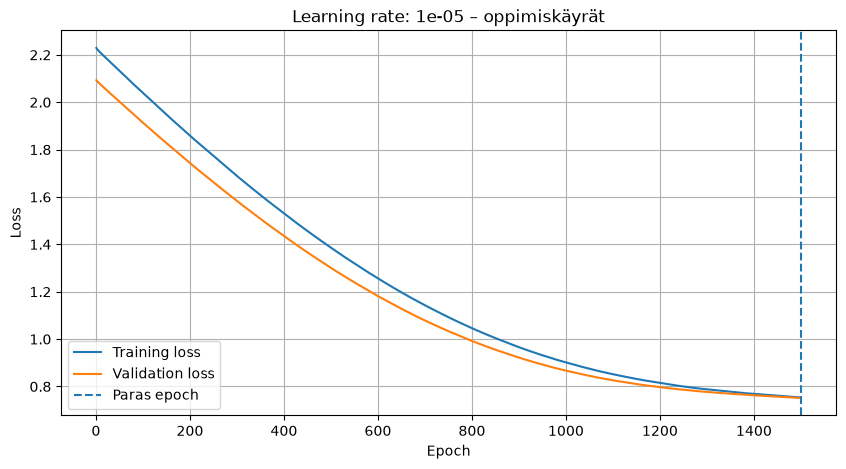

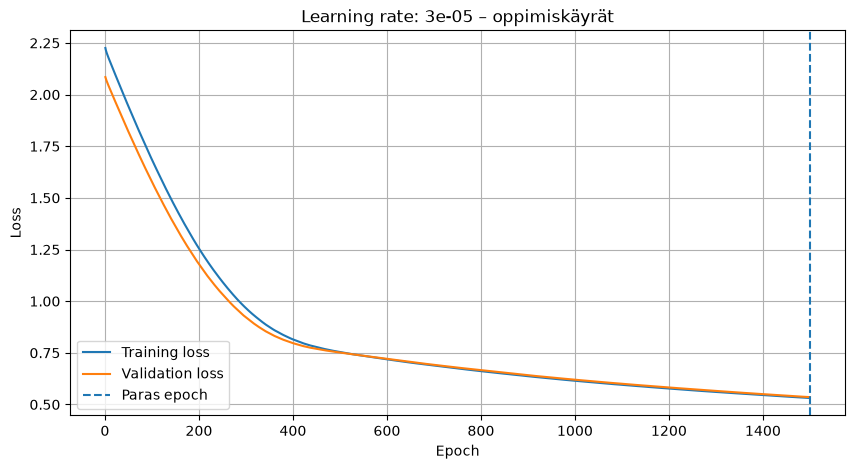

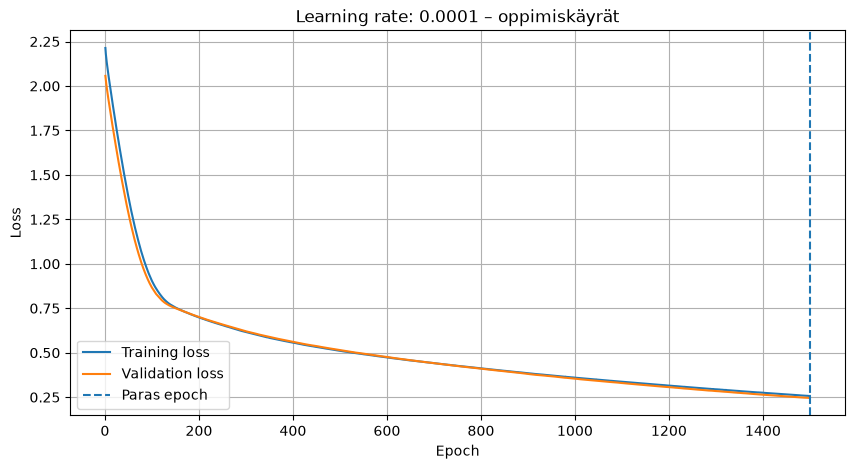

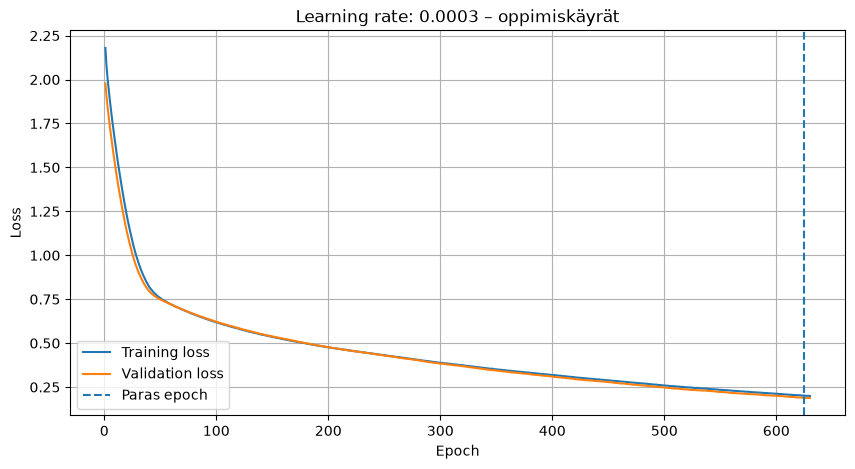

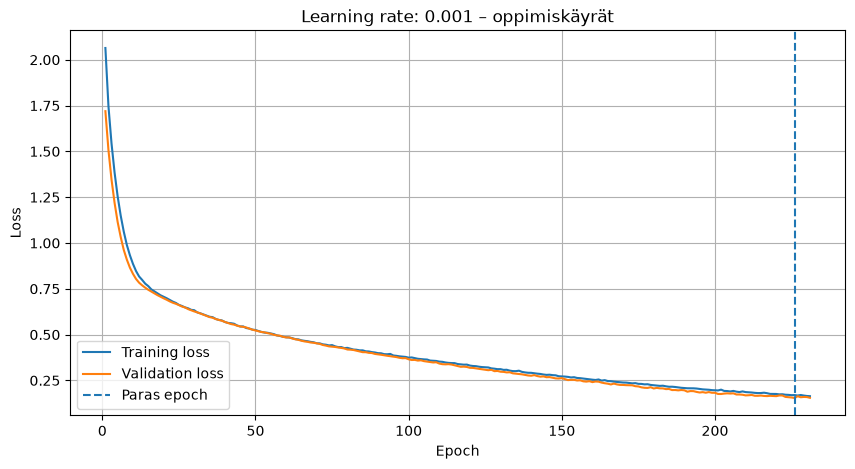

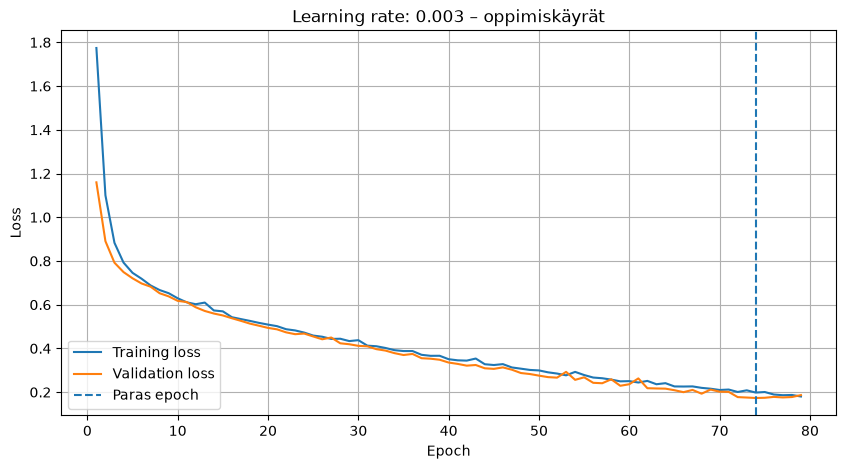

In [24]:
# Piirretään jokaisen learning raten training loss ja validation loss
for learning_rate, history in sorted(lr_histories.items()):
    best_epoch = np.argmin(history.history["val_loss"]) + 1
    epochs = range(1, len(history.history["loss"]) + 1)

    plt.figure(figsize=(10, 5))
    plt.plot(epochs, history.history["loss"], label="Training loss")
    plt.plot(epochs, history.history["val_loss"], label="Validation loss")
    plt.axvline(best_epoch, linestyle="--", label="Paras epoch")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Learning rate: {learning_rate} – oppimiskäyrät")
    plt.legend()
    plt.grid(True)
    plt.show()


## Johtopäätökset

Learning rate vaikuttaa siihen, kuinka nopeasti malli oppii ja kuinka paljon validation loss -käyrä vaihtelee. Liian pieni learningrate vaatii useamman koulutus syklin eli hylätään kaikki alle 0.001 toistaiseksi. 0.003 lisäsi kohinaa taas joten pysytään 0.001 vaikka se ei vielä päässyt tavoitteeseen vaan jäi 93.33%. 

## Batch size -kokeilu

Kokeillaan, saataisiinko batch sizeä muokkaamalla parempi tulos. Kokeillaan 8, 16, 32, 48 ja 64. Pidetään muut asetukset samoina: 16 neuronia ja learning rate 0.001.

In [25]:
import time

batch_sizes = [8, 16, 32, 48, 64]

batch_histories = {}
batch_training_times = {}

for batch_size in batch_sizes:
    keras.utils.set_random_seed(0)

    model = Sequential([
        Input(shape=(4,)),
        Flatten(),
        Dense(16, activation="relu"),
        Dense(3, activation="softmax")
    ])

    model.compile(
        optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    keras.utils.set_random_seed(0)

    start = time.perf_counter()

    history = model.fit(
        x_shuffled,
        y_shuffled,
        epochs=max_epochs,
        batch_size=batch_size,
        validation_split=0.2,
        callbacks=[stopper],
        verbose=0
    )

    elapsed = time.perf_counter() - start

    batch_histories[batch_size] = history
    batch_training_times[batch_size] = elapsed

    print(f"Batch size {batch_size}: {elapsed:.2f} s")

Batch size 8: 5.81 s
Batch size 16: 4.40 s
Batch size 32: 3.91 s
Batch size 48: 3.93 s
Batch size 64: 4.36 s


In [26]:
results = []

for batch_size, history in batch_histories.items():
    best_idx = np.argmin(history.history["val_loss"])

    results.append({
        "Batch size": batch_size,
        "Paras epoch": best_idx + 1,
        "Training loss": history.history["loss"][best_idx],
        "Validation loss": history.history["val_loss"][best_idx],
        "Training accuracy": history.history["accuracy"][best_idx],
        "Validation accuracy": history.history["val_accuracy"][best_idx],
        "Koulutusaika (s)": batch_training_times[batch_size]
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Batch size,Paras epoch,Training loss,Validation loss,Training accuracy,Validation accuracy,Koulutusaika (s)
0,8,103,0.1437,0.1234,0.9833,0.9667,5.8099
1,16,143,0.1636,0.1454,0.9750,0.9333,4.4019
2,32,226,0.1701,0.1541,0.9833,0.9333,3.9138
3,48,268,0.1839,0.1621,0.9833,0.9667,3.9276
4,64,357,0.1710,0.1573,0.9833,0.9333,4.3561


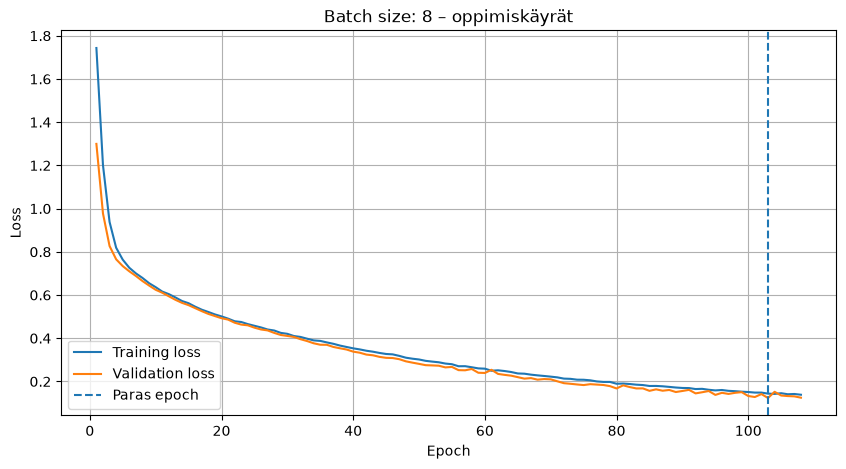

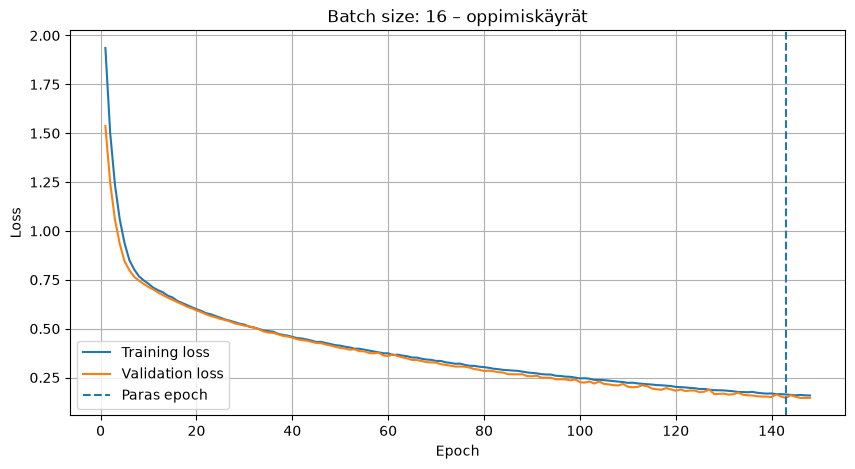

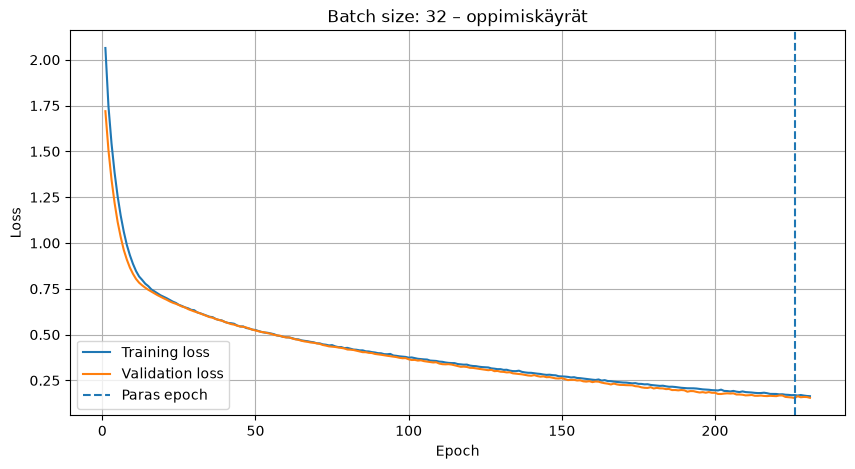

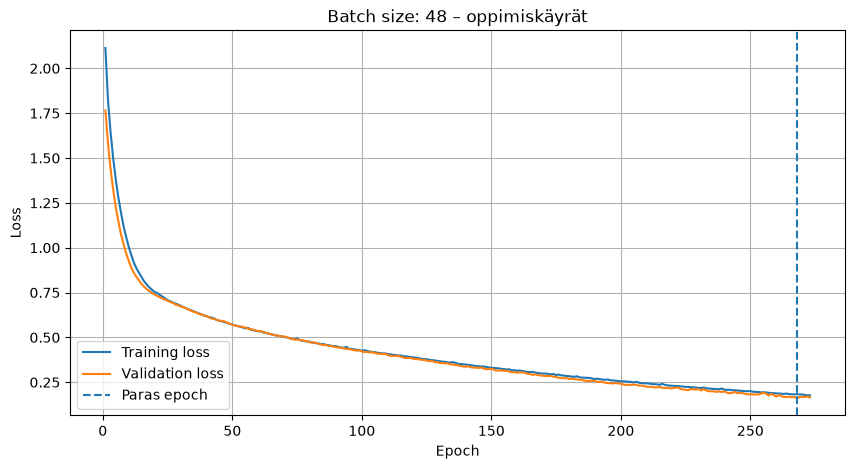

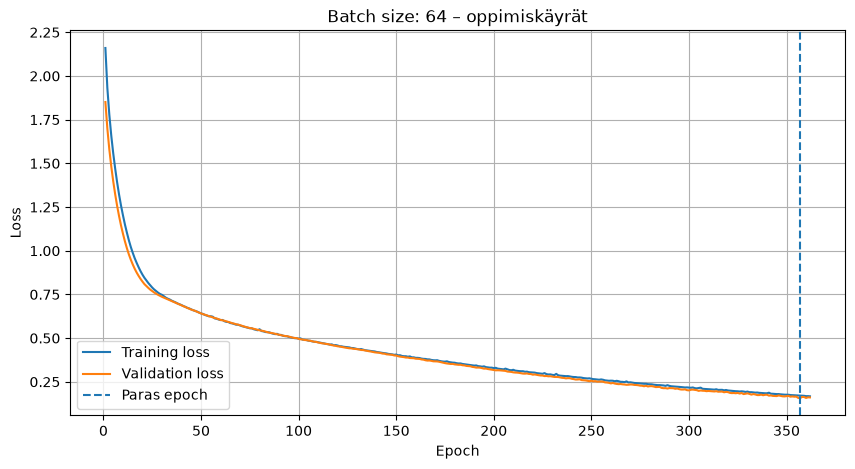

In [27]:
# Piirretään jokaisen batch sizen training loss ja validation loss
for batch_size, history in batch_histories.items():
    best_epoch = np.argmin(history.history["val_loss"]) + 1
    epochs = range(1, len(history.history["loss"]) + 1)

    plt.figure(figsize=(10, 5))
    plt.plot(epochs, history.history["loss"], label="Training loss")
    plt.plot(epochs, history.history["val_loss"], label="Validation loss")
    plt.axvline(best_epoch, linestyle="--", label="Paras epoch")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Batch size: {batch_size} – oppimiskäyrät")
    plt.legend()
    plt.grid(True)
    plt.show()


## Johtopäätökset

Batch sizeä kasvattamalla kohina pienenee. Kun painokertoimia päivitetään liian tiheästi, kohina kasvoi. Vajaaksi jäänyt ei päässyt tulokseen. Batchsize 8 pääsi jo haluttuun eli validointi tarkkuus oli 96,67%. 16 ja 32 eivät yltäneet tavoitteeseen vaikka kohina tasottui. Batch sizellä 48 sai myös 96,67% ja sen kohina oli paljon pienempi verrattaen 8 kohinaan. 48 toi hyvän tasapainon painojen päivityksille ja tarkkuudelle. Sen koulutus- ja validointitarkkuus olivat lähes samoja ja kohina pienempää verrattuna 8 batch malliin. 64 ei päässyt tavoitteeseen, vaikka kohina laski suhteellisen selkeästi.

## Viimeinen malli

Kokeillaan vielä lopullista mallia, jossa on 16 neuronia, learning rate 0.001 ja batch size 48. Maksimi kierrokset eli epochs saadaan yllä olevasta testistä ja asetetaan se 268. Tarkistetaan koulutus- ja validointitarkkuudet sekä loss-käyrä, jotta nähdään, onko ylioppimisesta merkkejä.

Training accuracy: 97.50%
Validation accuracy: 96.67%
Training loss: 0.181318
Validation loss: 0.162127


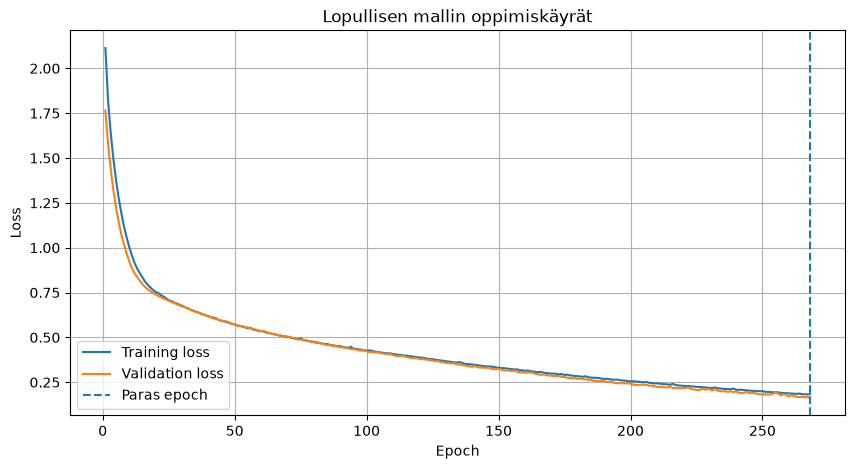

In [28]:
# Lopullinen optimoitu malli
keras.utils.set_random_seed(0)

final_epochs = 268
final_neurons = 16
final_learning_rate = 0.001
final_batch_size = 48

final_model = Sequential([
    Input(shape=(4,)),
    Flatten(),
    Dense(final_neurons, activation="relu"),
    Dense(3, activation="softmax")
])

final_model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=final_learning_rate),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Käytetään aiemmin sekoitettua dataa ilman standardointia
final_history = final_model.fit(
    x_shuffled,
    y_shuffled,
    epochs=final_epochs,
    batch_size=final_batch_size,
    validation_split=0.2,
    verbose=0
)

# Tarkistetaan mallin suorituskyky koulutuksen jälkeen
train_loss, train_acc = final_model.evaluate(
    x_shuffled[:train_size],
    y_shuffled[:train_size],
    verbose=0
)

val_loss, val_acc = final_model.evaluate(
    x_shuffled[train_size:],
    y_shuffled[train_size:],
    verbose=0
)

best_epoch = np.argmin(final_history.history["val_loss"]) + 1

print(f"Training accuracy: {train_acc:.2%}")
print(f"Validation accuracy: {val_acc:.2%}")
print(f"Training loss: {train_loss:.6f}")
print(f"Validation loss: {val_loss:.6f}")

# Piirretään koko koulutushistoria
epochs = range(1, len(final_history.history["loss"]) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs, final_history.history["loss"], label="Training loss")
plt.plot(epochs, final_history.history["val_loss"], label="Validation loss")
plt.axvline(best_epoch, linestyle="--", label="Paras epoch")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Lopullisen mallin oppimiskäyrät")
plt.legend()
plt.grid(True)
plt.show()

## Loppu yhteenveto

Malli pääsi tavoitteeseen treenitarkkuudella 97,5 ja validointitarkkuudella 96,67%. Molemmat lossit olivat alle 0.2 ja heittelyä että ylioppimista ei ole havaittavavissa, kun käyrät menevät saman suuntaisina, eilä validation loss lähtenyt nousemaan lopussa.